# Tech Challenge - Fase 2 | Classificação da qualidade de vinhos

## Introdução

Este notebook tem como objetivo desenvolver um modelo de classificação capaz de prever se um vinho é de alta qualidade a partir das suas características físico-químicas.

A base utilizada é a Wine Quality Dataset, disponível no Kaggle (https://www.kaggle.com/datasets/yasserh/wine-quality-dataset). Ela contém amostras de vinho tinto com 11 medidas de laboratório e uma nota de qualidade atribuída por especialistas.

A análise segue as etapas do ciclo de um projeto de Machine Learning: entendimento do problema, análise exploratória, pré processamento dos dados, treinamento dos modelos, avaliação e interpretação dos resultados.


In [1]:
#Bibliotecas utilizadas
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split, GridSearchCV, KFold, cross_val_score
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             classification_report, ConfusionMatrixDisplay, roc_curve, auc, make_scorer)

sns.set_style("whitegrid")

## Entendimento do problema

A avaliação da qualidade de um vinho é feita por especialistas, em uma análise sensorial que leva tempo e depende da experiência de quem avalia. A ideia aqui é verificar se as medidas de laboratório, que já são coletadas durante a produção, conseguem antecipar essa avaliação.

Para simplificar o problema, a nota de qualidade foi transformada em duas classes, conforme o enunciado: vinhos com nota maior ou igual a 7 são considerados de alta qualidade (1) e os demais de baixa ou média qualidade (0). Trata-se, portanto, de um problema de classificação binária.

## Análise exploratória dos dados

### Importação e composição da base

In [2]:
df_vinhos = pd.read_csv("WineQT.csv")
df_vinhos.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,2
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,3
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,4


In [3]:
df_vinhos.tail()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
1138,6.3,0.510,0.13,2.3,0.076,29.0,40.0,0.99574,3.42,0.75,11.0,6,1592
1139,6.8,0.620,0.08,1.9,0.068,28.0,38.0,0.99651,3.42,0.82,9.5,6,1593
1140,6.2,0.600,0.08,2.0,0.090,32.0,44.0,0.99490,3.45,0.58,10.5,5,1594
1141,5.9,0.550,0.10,2.2,0.062,39.0,51.0,0.99512,3.52,0.76,11.2,6,1595
1142,5.9,0.645,0.12,2.0,0.075,32.0,44.0,0.99547,3.57,0.71,10.2,5,1597


In [4]:
df_vinhos.shape

(1143, 13)

In [5]:
df_vinhos.info()
#todas as colunas são numéricas, não é necessário converter tipos
#a coluna Id é só o número da linha e não descreve o vinho

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1143 entries, 0 to 1142
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1143 non-null   float64
 1   volatile acidity      1143 non-null   float64
 2   citric acid           1143 non-null   float64
 3   residual sugar        1143 non-null   float64
 4   chlorides             1143 non-null   float64
 5   free sulfur dioxide   1143 non-null   float64
 6   total sulfur dioxide  1143 non-null   float64
 7   density               1143 non-null   float64
 8   pH                    1143 non-null   float64
 9   sulphates             1143 non-null   float64
 10  alcohol               1143 non-null   float64
 11  quality               1143 non-null   int64  
 12  Id                    1143 non-null   int64  
dtypes: float64(11), int64(2)
memory usage: 116.2 KB


### Preparação da base

As colunas foram renomeadas para português para facilitar a leitura e a coluna Id foi removida, pois é só o número da linha e não é uma descrição do vinho

In [6]:
df_vinhos = df_vinhos.drop(columns=["Id"])
df_vinhos = df_vinhos.rename(columns={
    "fixed acidity": "acidez_fixa",
    "volatile acidity": "acidez_volatil",
    "citric acid": "acido_citrico",
    "residual sugar": "acucar_residual",
    "chlorides": "cloretos",
    "free sulfur dioxide": "so2_livre",
    "total sulfur dioxide": "so2_total",
    "density": "densidade",
    "pH": "ph",
    "sulphates": "sulfatos",
    "alcohol": "alcool",
    "quality": "qualidade"})
df_vinhos.columns

Index(['acidez_fixa', 'acidez_volatil', 'acido_citrico', 'acucar_residual',
       'cloretos', 'so2_livre', 'so2_total', 'densidade', 'ph', 'sulfatos',
       'alcool', 'qualidade'],
      dtype='object')

In [7]:
#verificando dados nulos
df_vinhos.isnull().sum()

,0
acidez_fixa,0
acidez_volatil,0
acido_citrico,0
acucar_residual,0
cloretos,0
so2_livre,0
so2_total,0
densidade,0
ph,0
sulfatos,0


In [8]:
#verificando dados duplicados
df_vinhos.duplicated().sum()

np.int64(125)

In [9]:
#não há dados nulos, mas há 125 linhas duplicadas, com as mesmas medidas e mesma nota,
#se ficarem na base, o mesmo vinho pode cair no treino e no teste e o resultado do modelo fica melhor do que realmente é
df_vinhos = df_vinhos.drop_duplicates().reset_index(drop=True)
print(f"Linhas após remover os duplicados: {df_vinhos.shape[0]}")

Linhas após remover os duplicados: 1018


In [10]:
#criando a variável alvo: 1 = alta qualidade (nota >= 7), 0 = baixa/média qualidade
df_vinhos["alta_qualidade"] = (df_vinhos["qualidade"] >= 7).astype(int)
df_vinhos[["qualidade", "alta_qualidade"]].head()

,qualidade,alta_qualidade
0,5,0
1,5,0
2,5,0
3,6,0
4,5,0


### Análise descritiva

In [11]:
variaveis = ["acidez_fixa", "acidez_volatil", "acido_citrico", "acucar_residual", "cloretos",
             "so2_livre", "so2_total", "densidade", "ph", "sulfatos", "alcool"]
df_vinhos[variaveis].describe().T

,count,mean,std,min,25%,50%,75%,max
acidez_fixa,1018.0,8.288507,1.741324,4.60000,7.100000,7.900000,9.100000,15.90000
acidez_volatil,1018.0,0.533541,0.183167,0.12000,0.390000,0.520000,0.645000,1.58000
acido_citrico,1018.0,0.268802,0.196229,0.00000,0.090000,0.250000,0.420000,1.00000
acucar_residual,1018.0,2.524411,1.314850,0.90000,1.900000,2.200000,2.600000,15.50000
cloretos,1018.0,0.087187,0.048506,0.01200,0.070000,0.079000,0.090000,0.61100
so2_livre,1018.0,15.648821,10.176525,1.00000,7.000000,13.000000,21.000000,68.00000
so2_total,1018.0,46.325639,33.123533,6.00000,21.000000,38.000000,62.000000,289.00000
densidade,1018.0,0.996700,0.001916,0.99007,0.995572,0.996665,0.997827,1.00369
ph,1018.0,3.311503,0.157775,2.74000,3.210000,3.310000,3.400000,4.01000
sulfatos,1018.0,0.656817,0.167542,0.33000,0.550000,0.620000,0.720000,2.00000


as variáveis estão em escalas bem diferentes: densidade fica perto de 1 e o so2_total chega a 289
para KNN e Regressão Logística vai ser preciso padronizar ou normalizar os dados

### Distribuição da variável alvo e balanceamento das classes

In [12]:
df_vinhos["qualidade"].value_counts().sort_index()

,count
qualidade,
3,6
4,33
5,433
6,409
7,122
8,15


In [13]:
df_vinhos["alta_qualidade"].value_counts(normalize=True)

,proportion
alta_qualidade,
0,0.865422
1,0.134578


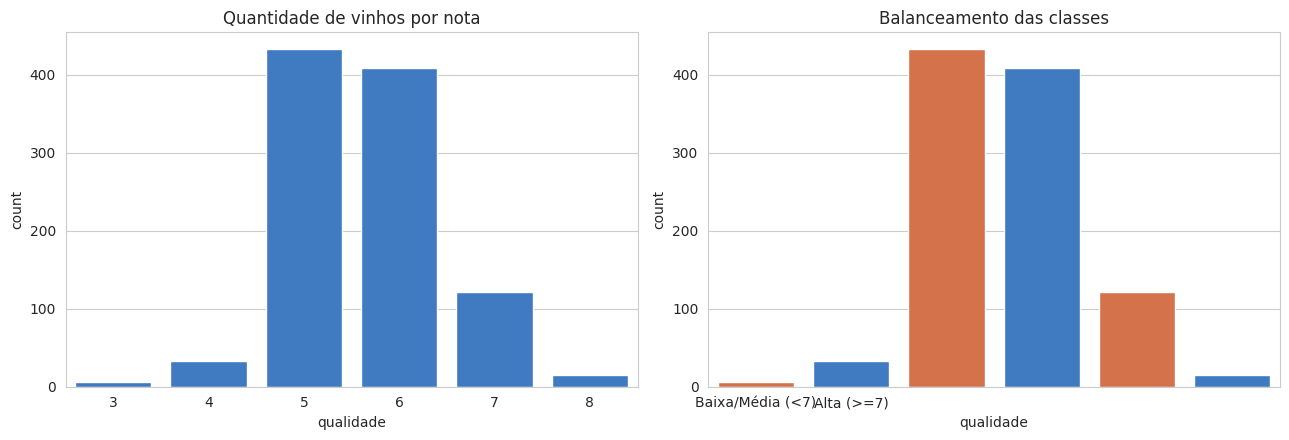

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.countplot(data=df_vinhos, x="qualidade", color="#2a78d6", ax=ax[0])
ax[0].set_title("Quantidade de vinhos por nota")
sns.countplot(data=df_vinhos, x="qualidade", palette=["#eb6834", "#2a78d6"], ax=ax[1])
ax[1].set_title("Balanceamento das classes")
ax[1].set_xticks([0, 1], ["Baixa/Média (<7)", "Alta (>=7)"])
plt.tight_layout()
plt.show()

As notas se concentram em 5 e 6, notas 3 e 8 são raras.

Apenas 13,5% dos vinhos são de alta qualidade (137 de 1.018), as classes estão desbalanceadas

### Distribuição das variáveis

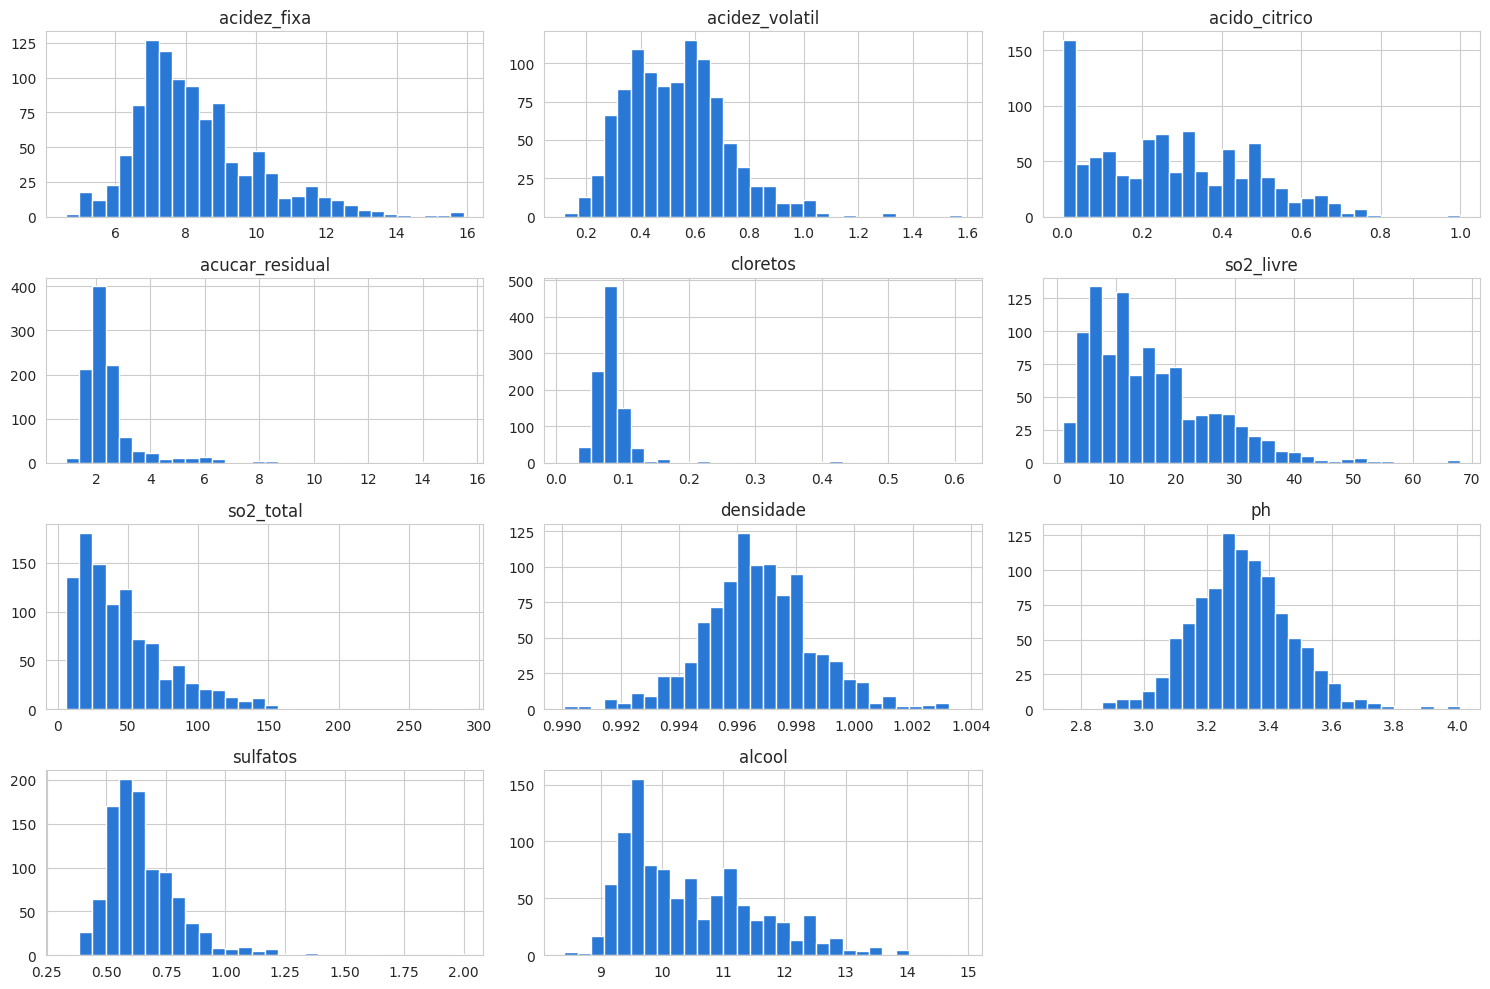

In [15]:
df_vinhos[variaveis].hist(bins=30, figsize=(15, 10), color="#2a78d6", edgecolor="white")
plt.tight_layout()
plt.show()

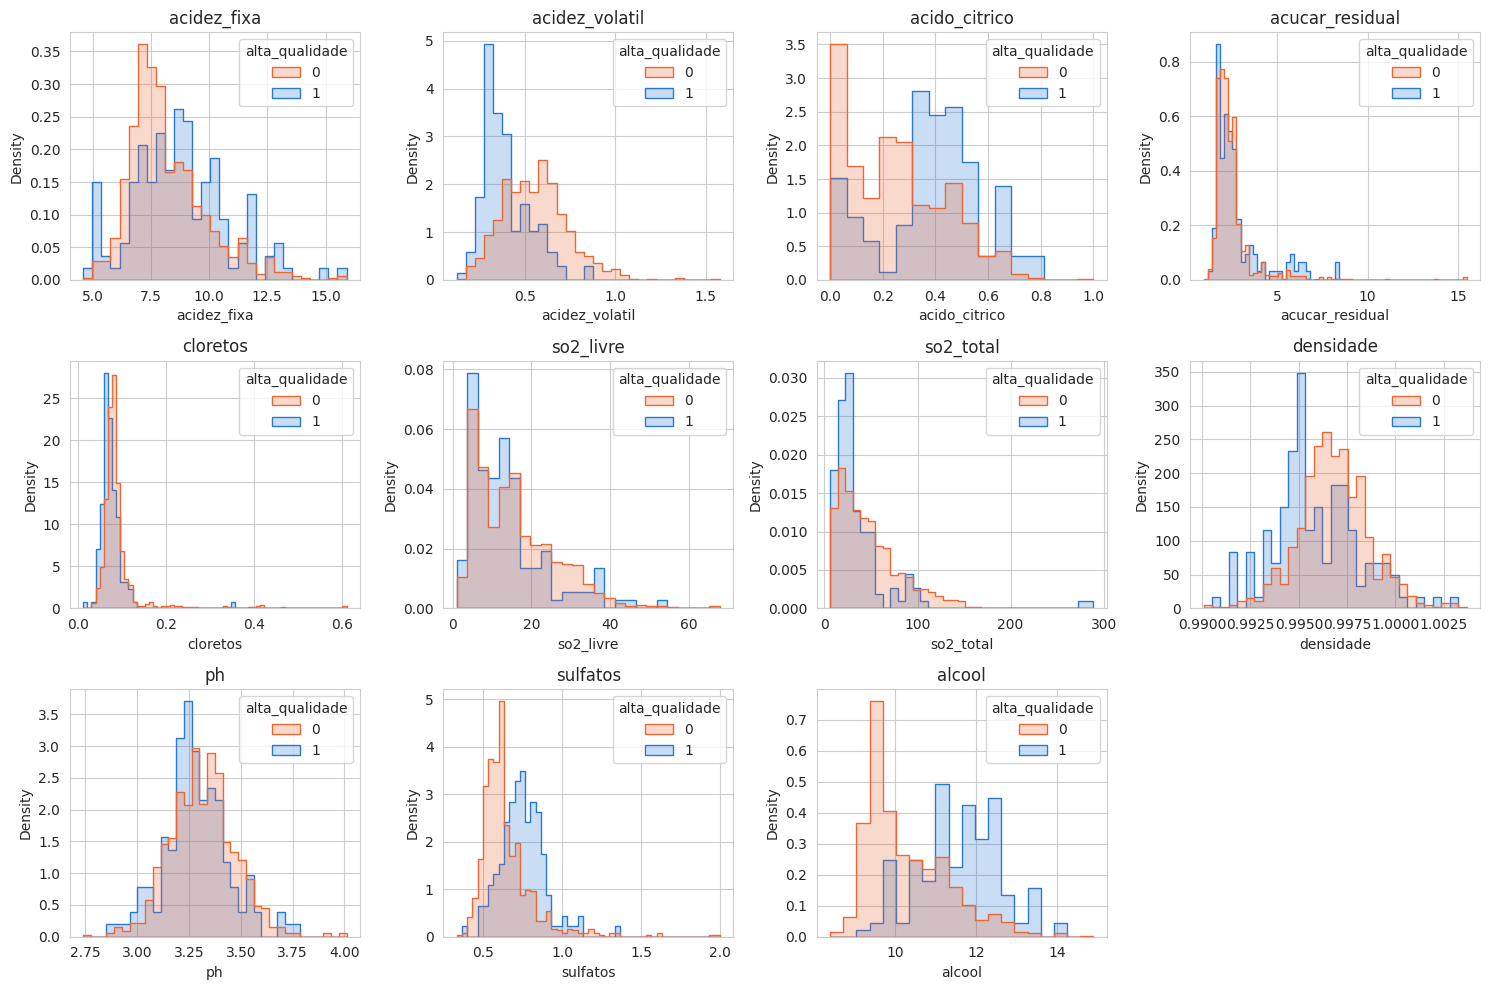

In [16]:
fig, axes = plt.subplots(3, 4, figsize=(15, 10))
for i, coluna in enumerate(variaveis):
    sns.histplot(data=df_vinhos, x=coluna, hue="alta_qualidade", stat="density", common_norm=False,
                 element="step", palette=["#eb6834", "#2a78d6"], ax=axes.flat[i])
    axes.flat[i].set_title(coluna)
axes.flat[-1].axis("off")
plt.tight_layout()
plt.show()

### Relação entre as variáveis

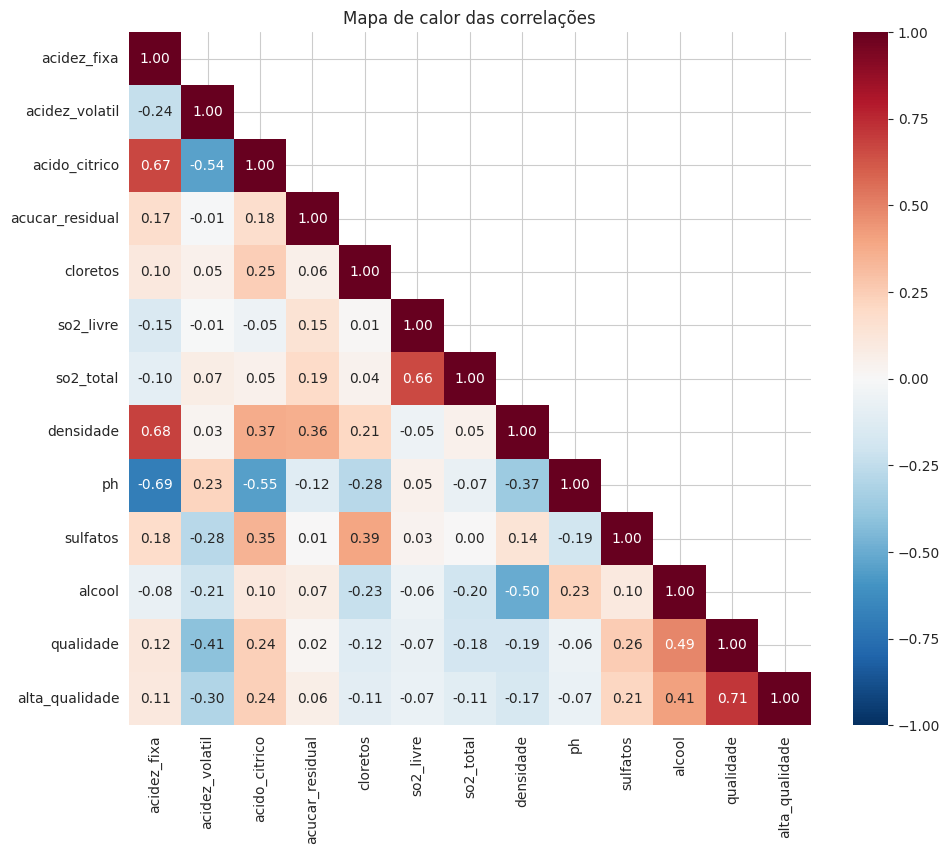

In [17]:
plt.figure(figsize=(11, 9))
correlacao = df_vinhos[variaveis + ["qualidade", "alta_qualidade"]].corr()
mascara = np.triu(np.ones_like(correlacao, dtype=bool), k=1)
sns.heatmap(correlacao, mask=mascara, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1)
plt.title("Mapa de calor das correlações")
plt.show()

Principais correlações entre as variáveis e a justificativa de cada uma:

Acidez fixa e pH (-0,69): quanto mais ácido o vinho, menor o pH, já que o pH mede a acidez em escala invertida.

Acidez fixa e densidade (+0,68): os ácidos dissolvidos deixam o líquido mais denso.

Acidez fixa e ácido cítrico (+0,67): o ácido cítrico é um dos ácidos que formam a acidez fixa.

SO₂ livre e SO₂ total (+0,66): o SO₂ livre é uma parte do SO₂ total.

Ácido cítrico e pH (-0,55): mais ácido cítrico significa pH menor.

Ácido cítrico e acidez volátil (-0,54): quando o vinho se deteriora, ele perde ácido cítrico e ganha ácido acético, que é o principal componente da acidez volátil.

Álcool e densidade (-0,50): o álcool é menos denso que a água e, na fermentação, o açúcar (mais denso) vira álcool.

Sulfatos e cloretos (+0,39): os dois são sais minerais dissolvidos no vinho.

Como algumas variáveis estão bem relacionadas entre si, é preciso cuidado ao interpretar cada uma isoladamente, principalmente na Regressão Logística.

In [18]:
correlacao["alta_qualidade"].drop(["alta_qualidade", "qualidade"]).sort_values()

,alta_qualidade
acidez_volatil,-0.302343
densidade,-0.166497
so2_total,-0.114990
cloretos,-0.105595
so2_livre,-0.067319
ph,-0.065270
acucar_residual,0.064405
acidez_fixa,0.107952
sulfatos,0.213071
acido_citrico,0.237369


Com a variável alvo, a maior correlação positiva é o alcool (0,41), seguido de acido_citrico (0,24) e sulfatos (0,21), a maior correlação negativa é a acidez_volatil (-0,30).

Densidade (-0,17), so2_total (-0,11) e cloretos (-0,11) também atrapalham, mas com menos força. Ph, so2_livre e acucar_residual quase não têm relação com a qualidade

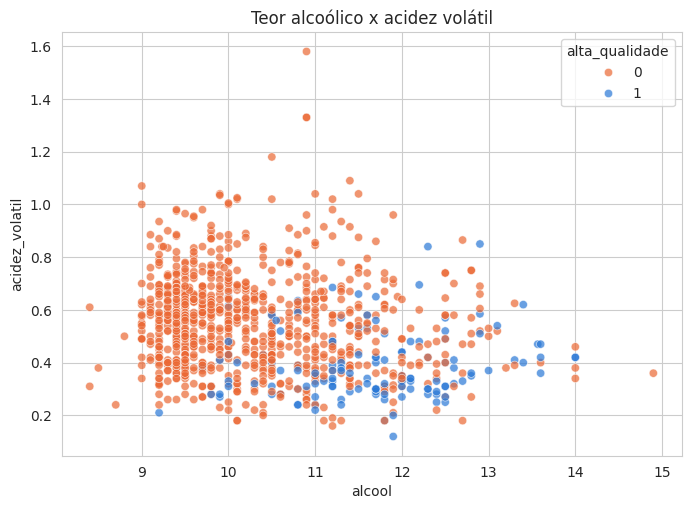

In [19]:
plt.figure(figsize=(8, 5.5))
sns.scatterplot(data=df_vinhos, x="alcool", y="acidez_volatil", hue="alta_qualidade",
                palette=["#eb6834", "#2a78d6"], alpha=0.7)
plt.title("Teor alcoólico x acidez volátil")
plt.show()

Os vinhos de alta qualidade se concentram onde o álcool é alto e a acidez volátil é baixa, mesmo assim as duas classes se misturam bastante, então o modelo pode cometer erros

### Outliers

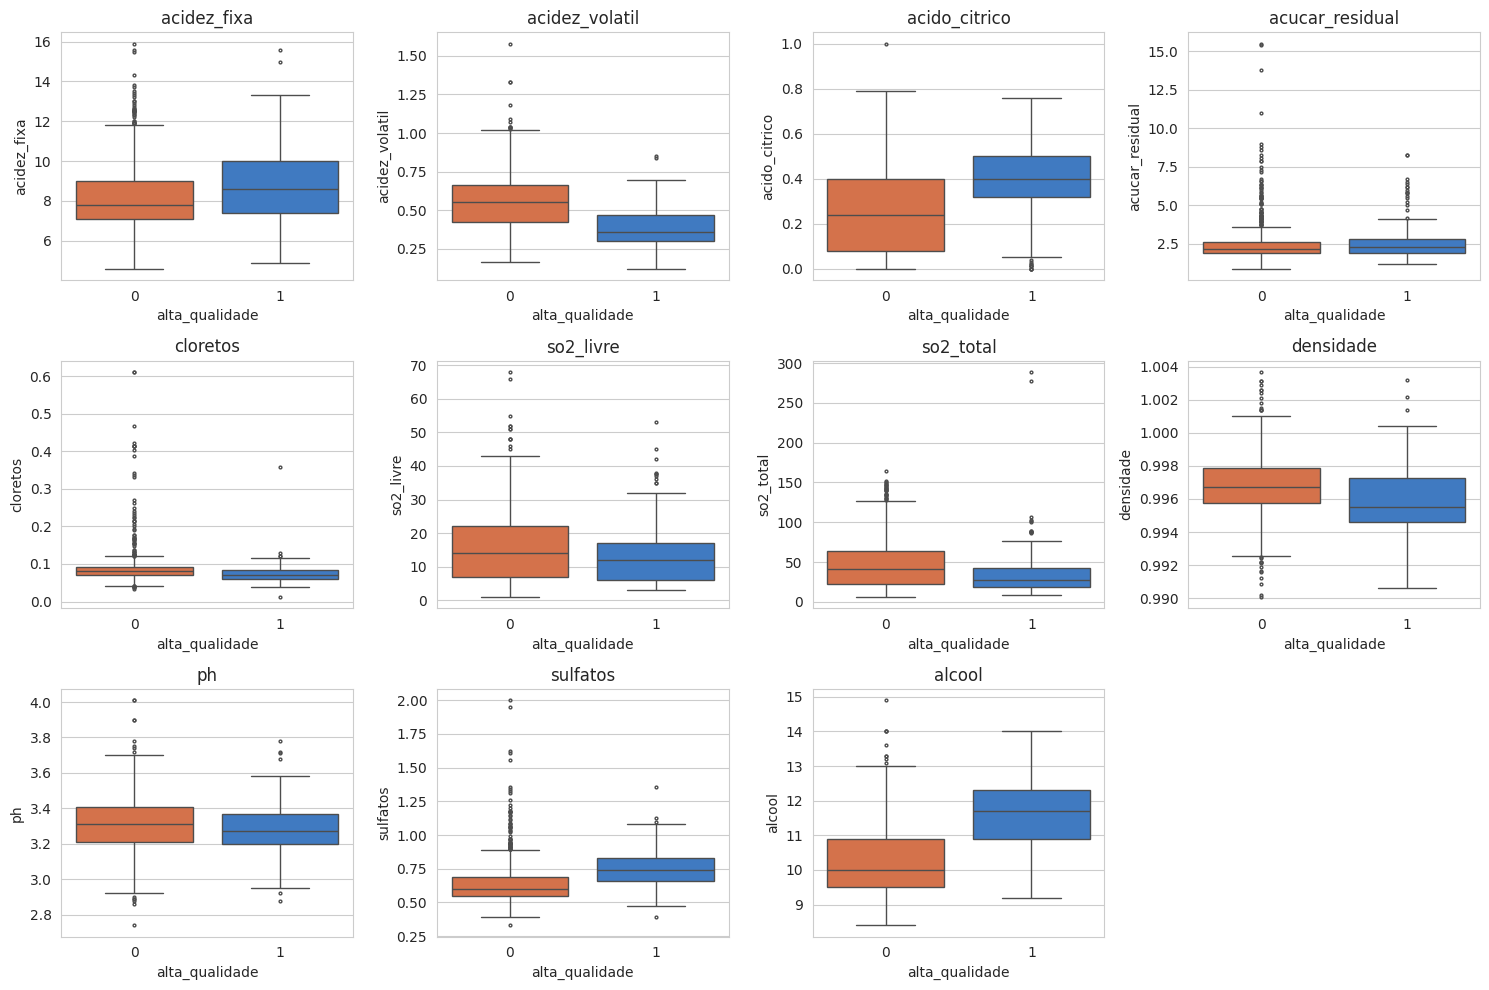

In [20]:
fig, axes = plt.subplots(3, 4, figsize=(15, 10))
for i, coluna in enumerate(variaveis):
    sns.boxplot(data=df_vinhos, x="alta_qualidade", y=coluna, palette=["#eb6834", "#2a78d6"],
                fliersize=2, ax=axes.flat[i])
    axes.flat[i].set_title(coluna)
axes.flat[-1].axis("off")
plt.tight_layout()
plt.show()

In [21]:
#quantidade de outliers por variável (pontos fora das pontas do boxplot)
q1 = df_vinhos[variaveis].quantile(0.25)
q3 = df_vinhos[variaveis].quantile(0.75)
iqr = q3 - q1
df_outliers = ((df_vinhos[variaveis] < q1 - 1.5 * iqr) | (df_vinhos[variaveis] > q3 + 1.5 * iqr)).sum()
df_outliers.sort_values(ascending=False)

,0
acucar_residual,95
cloretos,71
sulfatos,41
acidez_fixa,37
so2_total,33
densidade,30
ph,24
so2_livre,16
acidez_volatil,10
alcool,6


Acucar_residual (95) e cloretos (71) têm mais outliers, seguidos de sulfatos e acidez_fixa.
Não foram encontrados valores inconsistentes: nada negativo, ph entre 2,7 e 4,0, álcool entre 8,4% e 14,9%

Os outliers são vinhos reais (com mais açúcar ou mais sal, por exemplo), então foram mantidos

A padronização mantém os outliers na base, só muda a escala, e o Random Forest é pouco sensível a eles

### Insights

In [22]:
#percentual de vinhos de alta qualidade por faixa de cada variável
for coluna in ["alcool", "acidez_volatil", "sulfatos", "acido_citrico"]:
    df_faixas = df_vinhos.groupby(pd.qcut(df_vinhos[coluna], q=5), observed=True).agg(
        vinhos=("alta_qualidade", "count"), pct_alta=("alta_qualidade", "mean"))
    print(coluna)
    print(df_faixas.round(3))
    print()

alcool
                          vinhos  pct_alta
alcool                                    
(8.399000000000001, 9.5]     271     0.007
(9.5, 9.9]                   156     0.038
(9.9, 10.5]                  193     0.078
(10.5, 11.4]                 207     0.174
(11.4, 14.9]                 191     0.408

acidez_volatil
                vinhos  pct_alta
acidez_volatil                  
(0.119, 0.37]      207     0.362
(0.37, 0.47]       204     0.137
(0.47, 0.58]       221     0.095
(0.58, 0.67]       184     0.049
(0.67, 1.58]       202     0.020

sulfatos
               vinhos  pct_alta
sulfatos                       
(0.329, 0.54]     225     0.036
(0.54, 0.59]      191     0.052
(0.59, 0.65]      209     0.067
(0.65, 0.756]     189     0.222
(0.756, 2.0]      204     0.309

acido_citrico
                vinhos  pct_alta
acido_citrico                   
(-0.001, 0.06]     206     0.063
(0.06, 0.2]        202     0.064
(0.2, 0.31]        209     0.038
(0.31, 0.46]       200     0.28

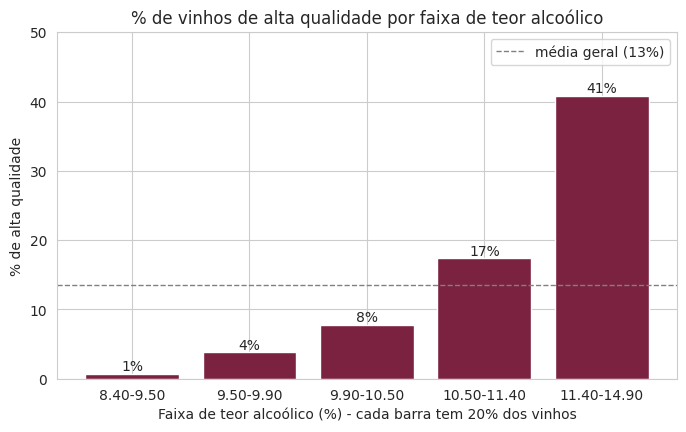

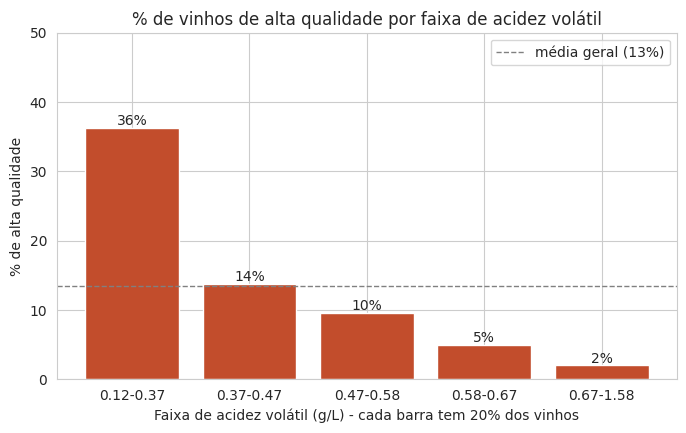

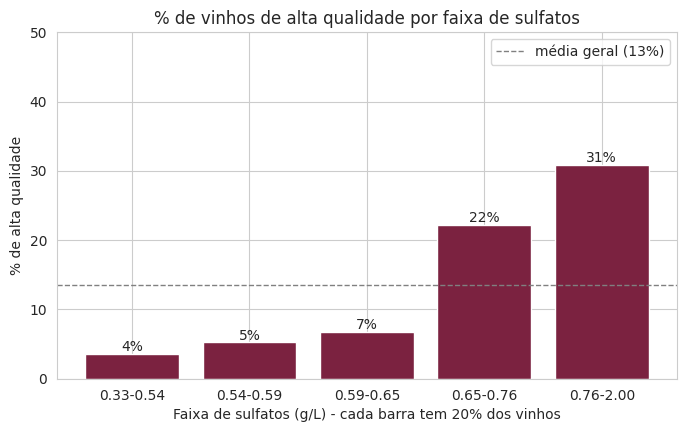

In [42]:
#gráficos do % de alta qualidade por faixa
graficos_faixas = {
    "alcool": ("Teor alcoólico", "%", "#7b2240"),
    "acidez_volatil": ("Acidez volátil", "g/L", "#c24d2c"),
    "sulfatos": ("Sulfatos", "g/L", "#7b2240"),
}

media_geral = df_vinhos["alta_qualidade"].mean()

for coluna, (nome, unidade, cor) in graficos_faixas.items():
    df_faixas = df_vinhos.groupby(pd.qcut(df_vinhos[coluna], q=5), observed=True)["alta_qualidade"].mean()
    nomes_faixas = [f"{faixa.left:.2f}-{faixa.right:.2f}" for faixa in df_faixas.index]

    plt.figure(figsize=(8, 4.5))
    barras = plt.bar(nomes_faixas, df_faixas.values * 100, color=cor)
    plt.bar_label(barras, labels=[f"{v:.0%}" for v in df_faixas.values])
    plt.axhline(media_geral * 100, color="gray", linestyle="--", linewidth=1, label=f"média geral ({media_geral:.0%})")
    plt.title(f"% de vinhos de alta qualidade por faixa de {nome.lower()}")
    plt.xlabel(f"Faixa de {nome.lower()} ({unidade}) - cada barra tem 20% dos vinhos")
    plt.ylabel("% de alta qualidade")
    plt.ylim(0, 50)
    plt.legend()
    plt.show()

In [23]:
df_perfil = df_vinhos[(df_vinhos["alcool"] >= 11) & (df_vinhos["acidez_volatil"] < 0.47) & (df_vinhos["sulfatos"] >= 0.65)]
print(f"Vinhos no perfil: {len(df_perfil)} ({len(df_perfil) / len(df_vinhos):.1%} da base)")
print(f"% de alta qualidade no perfil: {df_perfil['alta_qualidade'].mean():.1%}")
print(f"% de todos os vinhos de alta qualidade que estão no perfil: {df_perfil['alta_qualidade'].sum() / df_vinhos['alta_qualidade'].sum():.1%}")
print(f"% de alta qualidade com álcool abaixo de 10%: {df_vinhos[df_vinhos['alcool'] < 10]['alta_qualidade'].mean():.1%}")

Vinhos no perfil: 108 (10.6% da base)
% de alta qualidade no perfil: 53.7%
% de todos os vinhos de alta qualidade que estão no perfil: 42.3%
% de alta qualidade com álcool abaixo de 10%: 1.9%


Álcool: a chance de alta qualidade vai de 1% na faixa mais baixa para 41% na faixa mais alta

Acidez volátil: 36% de alta qualidade quando ela é baixa e só 2% quando é alta

Sulfatos acima de 0,65 triplicam a chance (22% a 31% contra 4% a 7%)

Ácido cítrico acima de 0,31: 23% a 28% contra 4% a 6%

Vinhos com álcool >= 11%, acidez volátil < 0,47 e sulfatos >= 0,65 são 11% da base, mas 54% deles são de alta qualidade (4x a média)

Esse grupo concentra 42% de todos os vinhos de alta qualidade

## Pré processamento dos dados

Não há variáveis categóricas, então não foi preciso usar Label Encoding ou One Hot Encoding.

### Criação de nova variável

Na análise exploratória, o SO₂ livre e o SO₂ total quase não tiveram relação com a qualidade quando olhados separadamente. Mas o SO₂ livre é a parte do SO₂ total que está ativa protegendo o vinho, então a proporção entre os dois pode dizer mais do que cada um sozinho. Por isso foi criada a variável proporcao_so2_livre.

In [24]:
df_vinhos["proporcao_so2_livre"] = df_vinhos["so2_livre"] / df_vinhos["so2_total"]
df_vinhos[["so2_livre", "so2_total", "proporcao_so2_livre", "alta_qualidade"]].corr()["alta_qualidade"]

,alta_qualidade
so2_livre,-0.067319
so2_total,-0.114990
proporcao_so2_livre,0.125064
alta_qualidade,1.000000


 A proporção tem correlação de 0,13 com a alta qualidade, maior do que o so2_livre (-0,07) e o so2_total (-0,11) separados

A base foi separada em 80% para treino e 20% para teste. O parâmetro stratify mantém a mesma proporção de vinhos de alta qualidade nas duas bases e o random_state garante que a divisão seja sempre a mesma.

In [25]:
variaveis_modelo = variaveis + ["proporcao_so2_livre"]
x = df_vinhos[variaveis_modelo]
y = df_vinhos["alta_qualidade"]

In [26]:
x_treino, x_teste, y_treino, y_teste = train_test_split(x, y, test_size=0.2, stratify=y, random_state=42)
print(f"Treino: {x_treino.shape[0]} vinhos | Teste: {x_teste.shape[0]} vinhos")
print(f"% de alta qualidade no treino: {y_treino.mean():.1%} | no teste: {y_teste.mean():.1%}")

Treino: 814 vinhos | Teste: 204 vinhos
% de alta qualidade no treino: 13.5% | no teste: 13.2%


In [27]:
#comparando a padronização e a normalização em três variáveis do treino
df_exemplo = x_treino[["densidade", "so2_total", "alcool"]]
df_padronizado = pd.DataFrame(StandardScaler().fit_transform(df_exemplo), columns=df_exemplo.columns)
df_normalizado = pd.DataFrame(MinMaxScaler().fit_transform(df_exemplo), columns=df_exemplo.columns)
print("Padronizado (média 0 e desvio 1)")
print(df_padronizado.describe().loc[["mean", "std", "min", "max"]].round(2))
print()
print("Normalizado (entre 0 e 1)")
print(df_normalizado.describe().loc[["mean", "std", "min", "max"]].round(2))

Padronizado (média 0 e desvio 1)
      densidade  so2_total  alcool
mean      -0.00       0.00   -0.00
std        1.00       1.00    1.00
min       -3.48      -1.19   -1.89
max        3.66       7.18    3.29

Normalizado (entre 0 e 1)
      densidade  so2_total  alcool
mean       0.49       0.14    0.37
std        0.14       0.12    0.19
min        0.00       0.00    0.00
max        1.00       1.00    1.00


KNN e Regressão Logística dependem da escala, então as duas opções (StandardScaler e MinMaxScaler) foram testadas no GridSearch

Oo Random Forest não precisa de escala

A escala fica dentro de um Pipeline para ser ajustada só com os dados de treino

In [28]:
#a nova variável ajuda os modelos? comparando o F1 na validação cruzada (só no treino) com e sem ela
kfold = KFold(n_splits=10, shuffle=True, random_state=42)
f1_scorer = make_scorer(f1_score)
modelos_teste = {
    "Regressão Logística": Pipeline([("escala", StandardScaler()), ("modelo", LogisticRegression(max_iter=1000))]),
    "KNN": Pipeline([("escala", StandardScaler()), ("modelo", KNeighborsClassifier())]),
    "Random Forest": RandomForestClassifier(random_state=42, n_jobs=-1)}

for nome, modelo in modelos_teste.items():
    sem = cross_val_score(modelo, x_treino[variaveis], y_treino, cv=kfold, scoring=f1_scorer).mean()
    com = cross_val_score(modelo, x_treino[variaveis_modelo], y_treino, cv=kfold, scoring=f1_scorer).mean()
    print(f"{nome}: F1 sem a variável = {sem:.3f} | com a variável = {com:.3f}")

Regressão Logística: F1 sem a variável = 0.405 | com a variável = 0.445
KNN: F1 sem a variável = 0.370 | com a variável = 0.438
Random Forest: F1 sem a variável = 0.431 | com a variável = 0.451


A nova variável melhorou o F1 dos três modelos, então ela foi mantida

A decisão foi tomada só com a validação cruzada no treino, sem olhar o conjunto de teste

## Modelos

Foram escolhidos três modelos de classificação com abordagens diferentes: a Regressão Logística (modelo linear), o KNN (baseado na distância entre os vinhos) e o Random Forest (conjunto de árvores de decisão).

Os hiperparâmetros foram escolhidos com GridSearchCV usando o F1 como métrica, já que a acurácia não funciona bem com classes desbalanceadas. O GridSearch usa o mesmo K-Fold de 10 folds das outras etapas, para que todos os resultados sejam comparáveis.

### GridSearchCV

In [29]:
modelos = {
    "Regressão Logística": (
        Pipeline([("escala", StandardScaler()), ("modelo", LogisticRegression(max_iter=1000, random_state=42))]),
        {"escala": [StandardScaler(), MinMaxScaler()], "modelo__C": [0.01, 0.1, 1, 10, 100]}),
    "KNN": (
        Pipeline([("escala", StandardScaler()), ("modelo", KNeighborsClassifier())]),
        {"escala": [StandardScaler(), MinMaxScaler()],
         "modelo__n_neighbors": [1, 3, 5, 7, 9, 11, 13, 15],
         "modelo__weights": ["uniform", "distance"],
         "modelo__metric": ["euclidean", "manhattan", "cosine"]}),
    "Random Forest": (
        Pipeline([("modelo", RandomForestClassifier(random_state=42, n_jobs=-1))]),
        {"modelo__n_estimators": [100, 300],
         "modelo__criterion": ["gini", "entropy"],
         "modelo__max_depth": [None, 5, 10],
         "modelo__min_samples_leaf": [1, 3, 5]}),
}

In [30]:
melhores_modelos = {}
for nome, (pipeline, parametros) in modelos.items():
    grid = GridSearchCV(pipeline, param_grid=parametros, scoring=f1_scorer, cv=kfold, n_jobs=-1)
    grid.fit(x_treino, y_treino)
    melhores_modelos[nome] = grid.best_estimator_
    print(f"{nome}: F1 = {grid.best_score_:.3f}")
    print(grid.best_params_)
    print()

Regressão Logística: F1 = 0.453
{'escala': MinMaxScaler(), 'modelo__C': 100}

KNN: F1 = 0.510
{'escala': StandardScaler(), 'modelo__metric': 'cosine', 'modelo__n_neighbors': 7, 'modelo__weights': 'distance'}

Random Forest: F1 = 0.475
{'modelo__criterion': 'entropy', 'modelo__max_depth': 10, 'modelo__min_samples_leaf': 1, 'modelo__n_estimators': 100}



### Escolha do k no KNN

Para conferir a escolha do GridSearch, o KNN foi testado com k de 1 a 20, mantendo a mesma escala, métrica de distância e pesos escolhidos. Para cada k foram calculados o erro médio e o F1 médio na validação cruzada do treino.

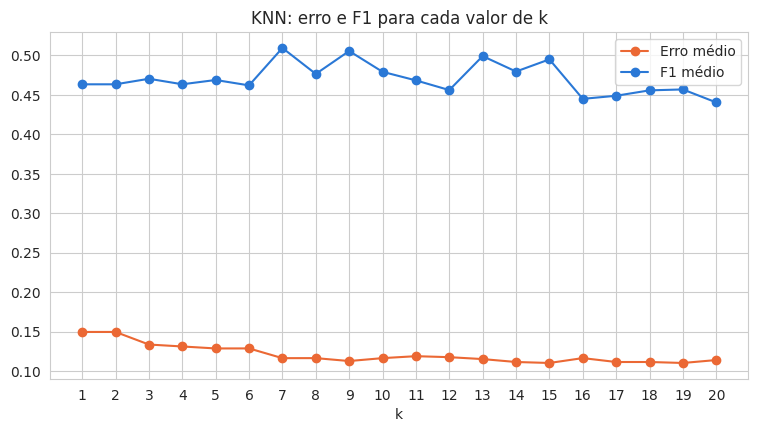

k com menor erro: 15 | k com maior F1: 7


In [31]:
knn_escolhido = melhores_modelos["KNN"]
escala = knn_escolhido.named_steps["escala"]
metrica = knn_escolhido.named_steps["modelo"].metric
pesos = knn_escolhido.named_steps["modelo"].weights

erros = []
f1s = []
for k in range(1, 21):
    knn = Pipeline([("escala", escala), ("modelo", KNeighborsClassifier(n_neighbors=k, metric=metrica, weights=pesos))])
    erros.append(1 - cross_val_score(knn, x_treino, y_treino, cv=kfold, scoring="accuracy").mean())
    f1s.append(cross_val_score(knn, x_treino, y_treino, cv=kfold, scoring=f1_scorer).mean())

plt.figure(figsize=(9, 4.5))
plt.plot(range(1, 21), erros, "-o", color="#eb6834", label="Erro médio")
plt.plot(range(1, 21), f1s, "-o", color="#2a78d6", label="F1 médio")
plt.title("KNN: erro e F1 para cada valor de k")
plt.xlabel("k")
plt.xticks(range(1, 21))
plt.legend()
plt.show()
print(f"k com menor erro: {np.argmin(erros) + 1} | k com maior F1: {np.argmax(f1s) + 1}")

Com k muito baixo o modelo fica sensível a ruído e com k muito alto ele tende a responder sempre a classe que mais aparece

O erro e o F1 nem sempre apontam para o mesmo k: o erro (acurácia) favorece a classe majoritária, enquanto o F1 olha para os vinhos bons, por isso a escolha final do k foi feita pelo F1

### Validação cruzada (K-Fold)

In [32]:
resultados_cv = []
for nome, modelo in melhores_modelos.items():
    f1 = cross_val_score(modelo, x_treino, y_treino, cv=kfold, scoring=f1_scorer)
    acuracia = cross_val_score(modelo, x_treino, y_treino, cv=kfold, scoring="accuracy")
    for fold in range(10):
        resultados_cv.append({"modelo": nome, "fold": fold + 1, "f1": f1[fold], "acuracia": acuracia[fold]})

df_cv = pd.DataFrame(resultados_cv)
df_cv.groupby("modelo").agg(f1_medio=("f1", "mean"), f1_desvio=("f1", "std"),
                            acuracia_media=("acuracia", "mean")).sort_values("f1_medio", ascending=False)

,f1_medio,f1_desvio,acuracia_media
modelo,,,
KNN,0.509523,0.151141,0.883348
Random Forest,0.475171,0.117235,0.898088
Regressão Logística,0.452769,0.131170,0.882069


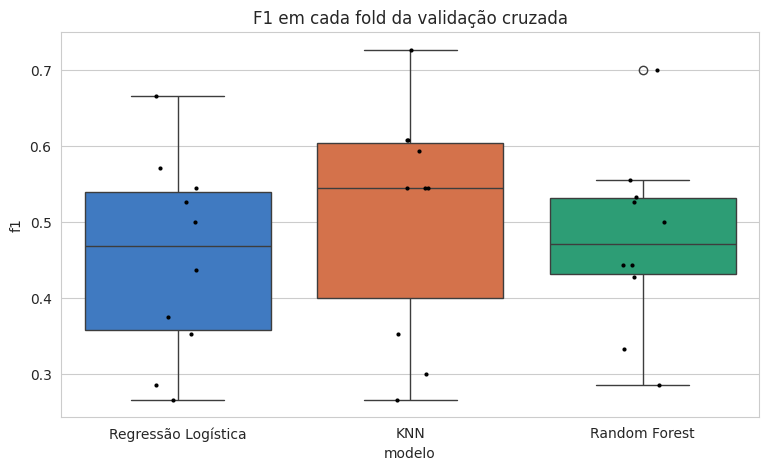

In [33]:
plt.figure(figsize=(9, 5))
sns.boxplot(data=df_cv, x="modelo", y="f1", palette=["#2a78d6", "#eb6834", "#1baf7a"])
sns.stripplot(data=df_cv, x="modelo", y="f1", color="black", size=3)
plt.title("F1 em cada fold da validação cruzada")
plt.show()

Os três modelos têm acurácia perto de 88%, quase igual a responder sempre baixa/média (86,5%)

No F1, o KNN tem a maior média (0,51), depois o Random Forest (0,48) e a Regressão Logística (0,45)

A diferença entre eles é pequena se comparada com a variação entre os folds (desvio entre 0,12 e 0,15)

## Avaliação dos modelos

Os modelos foram avaliados no conjunto de teste, que não foi usado em nenhuma etapa do treinamento. As métricas utilizadas foram a matriz de confusão, a acurácia, a precisão, o recall, o F1 e a curva ROC com a AUC.

In [34]:
resultados = {}
for nome, modelo in melhores_modelos.items():
    previsao = modelo.predict(x_teste)
    probabilidade = modelo.predict_proba(x_teste)[:, 1]
    resultados[nome] = {
        "acuracia": accuracy_score(y_teste, previsao),
        "precisao": precision_score(y_teste, previsao),
        "recall": recall_score(y_teste, previsao),
        "f1_teste": f1_score(y_teste, previsao),
        "auc": roc_auc_score(y_teste, probabilidade),
        "f1_treino": f1_score(y_treino, modelo.predict(x_treino))}

df_resultados = pd.DataFrame(resultados).T
df_resultados.round(3)

,acuracia,precisao,recall,f1_teste,auc,f1_treino
Regressão Logística,0.897,0.650,0.481,0.553,0.888,0.514
KNN,0.887,0.600,0.444,0.511,0.883,1.000
Random Forest,0.907,0.786,0.407,0.537,0.912,1.000


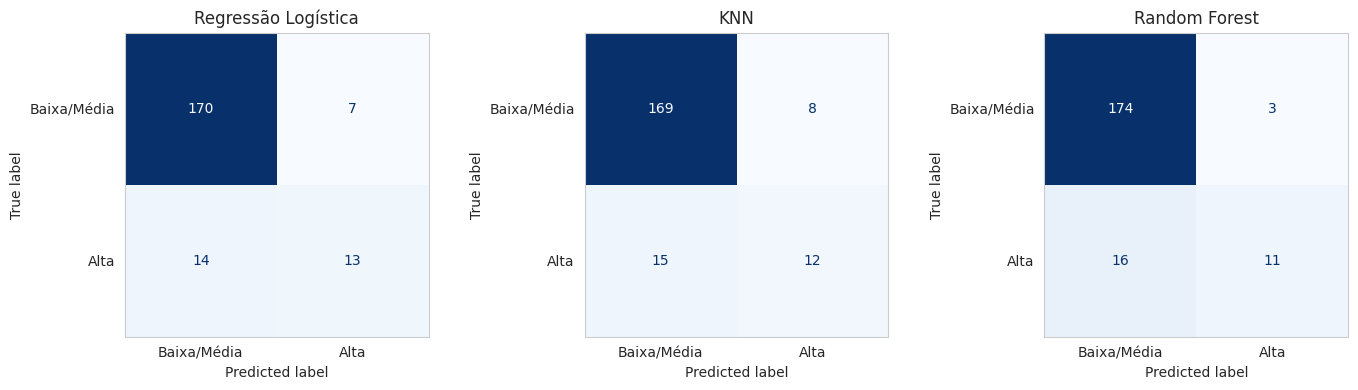

In [35]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (nome, modelo) in zip(axes, melhores_modelos.items()):
    ConfusionMatrixDisplay.from_estimator(modelo, x_teste, y_teste, display_labels=["Baixa/Média", "Alta"], cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(nome)
    ax.grid(False)
plt.tight_layout()
plt.show()

In [36]:
for nome, modelo in melhores_modelos.items():
    print(nome)
    print(classification_report(y_teste, modelo.predict(x_teste), target_names=["Baixa/Média", "Alta"], digits=3))

Regressão Logística
              precision    recall  f1-score   support

 Baixa/Média      0.924     0.960     0.942       177
        Alta      0.650     0.481     0.553        27

    accuracy                          0.897       204
   macro avg      0.787     0.721     0.748       204
weighted avg      0.888     0.897     0.890       204

KNN
              precision    recall  f1-score   support

 Baixa/Média      0.918     0.955     0.936       177
        Alta      0.600     0.444     0.511        27

    accuracy                          0.887       204
   macro avg      0.759     0.700     0.723       204
weighted avg      0.876     0.887     0.880       204

Random Forest
              precision    recall  f1-score   support

 Baixa/Média      0.916     0.983     0.948       177
        Alta      0.786     0.407     0.537        27

    accuracy                          0.907       204
   macro avg      0.851     0.695     0.742       204
weighted avg      0.899     0.907   

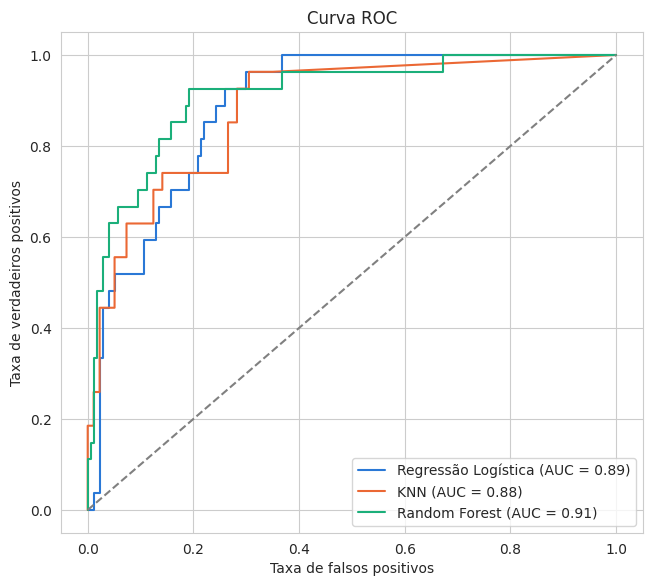

In [37]:
plt.figure(figsize=(7.5, 6.5))
for (nome, modelo), cor in zip(melhores_modelos.items(), ["#2a78d6", "#eb6834", "#1baf7a"]):
    probabilidade = modelo.predict_proba(x_teste)[:, 1]
    taxa_fp, taxa_vp, limiares = roc_curve(y_teste, probabilidade)
    plt.plot(taxa_fp, taxa_vp, color=cor, label=f"{nome} (AUC = {auc(taxa_fp, taxa_vp):.2f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray")
plt.title("Curva ROC")
plt.xlabel("Taxa de falsos positivos")
plt.ylabel("Taxa de verdadeiros positivos")
plt.legend(loc="lower right")
plt.show()

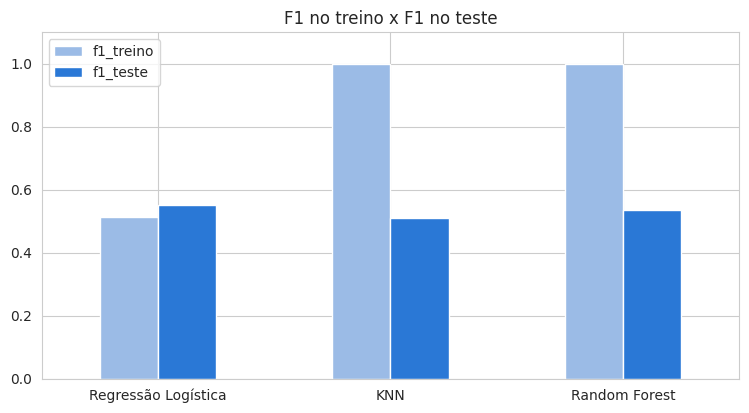

In [38]:
df_resultados[["f1_treino", "f1_teste"]].plot(kind="bar", figsize=(9, 4.5), color=["#9bbbe6", "#2a78d6"], rot=0)
plt.title("F1 no treino x F1 no teste")
plt.ylim(0, 1.1)
plt.show()

Os três modelos têm AUC entre 0,88 e 0,91, bem acima de 0,5 (modelo aleatório)

Random Forest: maior AUC (0,91) e maior precisão (79%), mas F1 de 1,00 no treino e 0,54 no teste, sinal de overfitting

KNN: o F1 de 1,00 no treino acontece por causa do weights="distance" (cada vinho do treino é o seu próprio vizinho mais próximo), então para o KNN vale olhar a validação cruzada e o teste, e não o treino

Regressão Logística: sem overfitting (0,51 no treino e 0,55 no teste) e o melhor F1 no teste, mas o menor F1 na validação cruzada

O modelo escolhido foi o KNN, por ter o maior F1 médio na validação cruzada. Esse critério foi definido antes de olhar o resultado no teste.

No teste, o KNN teve acurácia de 89%, precisão de 60% e recall de 44%. Na prática, dos 20 vinhos que ele apontou como de alta qualidade, 12 realmente eram (6 em cada 10, contra pouco mais de 1 em 7 se a escolha fosse ao acaso). Por outro lado, ele encontrou 12 dos 27 vinhos de alta qualidade do teste, ou seja, deixou passar mais da metade.

No teste, o KNN ficou com F1 um pouco menor que a Regressão Logística (0,51 contra 0,55) e o Random Forest (0,54). A diferença corresponde a um ou dois vinhos: o KNN encontrou 12 vinhos bons, a Regressão Logística 13 e o Random Forest 11. Como o teste tem apenas 27 vinhos de alta qualidade, poucos acertos a mais ou a menos mudam bastante as métricas. Por isso a escolha foi mantida pela validação cruzada, que usa mais dados, e não pelo resultado do teste.

Sobre o recall: os três modelos deixam passar parte dos vinhos bons. Existe uma troca entre precisão e recall, e com poucos exemplos de alta qualidade na base é difícil melhorar os dois ao mesmo tempo. A forma mais segura de aumentar o recall é ter mais dados de vinhos de alta qualidade.

## Interpretação dos resultados

O KNN não mostra quais variáveis pesam mais na decisão, porque ele compara vinhos parecidos. Para entender a influência das variáveis foi usada a importância (Gini) do Random Forest.

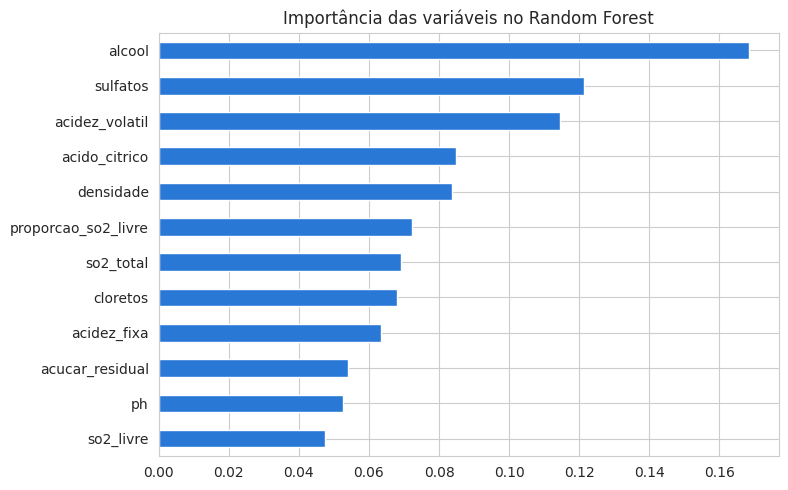

,0
alcool,0.168
sulfatos,0.121
acidez_volatil,0.115
acido_citrico,0.085
densidade,0.084
proporcao_so2_livre,0.072
so2_total,0.069
cloretos,0.068
acidez_fixa,0.063
acucar_residual,0.054


In [39]:
df_importancia = pd.Series(melhores_modelos["Random Forest"].named_steps["modelo"].feature_importances_,
                           index=variaveis_modelo).sort_values()
df_importancia.plot(kind="barh", figsize=(8, 5.5), color="#2a78d6")
plt.title("Importância das variáveis no Random Forest")
plt.show()
df_importancia.sort_values(ascending=False).round(3)

A importância do Random Forest confirma o que apareceu na análise exploratória

Álcool (16,8%), sulfatos (12,1%) e acidez_volatil (11,5%) são as variáveis mais importantes, seguidas de acido_citrico e densidade

A variável criada (proporcao_so2_livre) aparece em 6º lugar (7,2%), acima do so2_livre e do so2_total separados

### Comparação Escolhas do Modelo x Escolhas ao acaso

Vinhos apontados como alta qualidade: 20
Precisão do KNN: 60%
Acerto escolhendo ao acaso: 13%
Quantas vezes melhor que o acaso: 4.5x
Recall do KNN: 44%


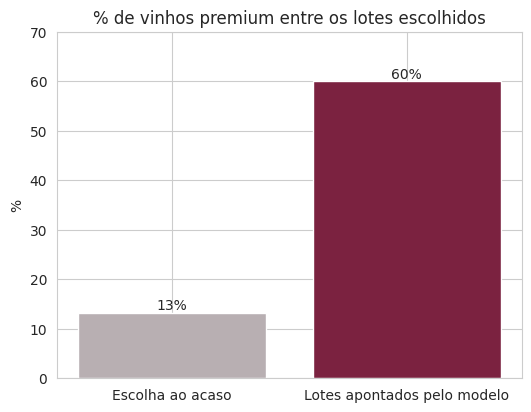

In [40]:
previsao_knn = melhores_modelos["KNN"].predict(x_teste)

precisao_knn = precision_score(y_teste, previsao_knn)
recall_knn = recall_score(y_teste, previsao_knn)
acerto_acaso = y_teste.mean()

print(f"Vinhos apontados como alta qualidade: {previsao_knn.sum()}")
print(f"Precisão do KNN: {precisao_knn:.0%}")
print(f"Acerto escolhendo ao acaso: {acerto_acaso:.0%}")
print(f"Quantas vezes melhor que o acaso: {precisao_knn / acerto_acaso:.1f}x")
print(f"Recall do KNN: {recall_knn:.0%}")

plt.figure(figsize=(6, 4.5))
barras = plt.bar(["Escolha ao acaso", "Lotes apontados pelo modelo"],
                 [acerto_acaso * 100, precisao_knn * 100], color=["#b8afb2", "#7b2240"])
plt.bar_label(barras, labels=[f"{acerto_acaso:.0%}", f"{precisao_knn:.0%}"])
plt.title("% de vinhos premium entre os lotes escolhidos")
plt.ylabel("%")
plt.ylim(0, 70)
plt.show()

## Conclusão

As variáveis com maior influência na qualidade do vinho são o teor alcoólico, os sulfatos e a acidez volátil, seguidos pela densidade e pelo ácido cítrico. Os mesmos fatores aparecem na análise exploratória, na importância do Random Forest. A variável criada, a proporção de SO₂ livre, melhorou o F1 dos três modelos na validação cruzada.

Para o processo de produção, os resultados indicam alguns pontos de atenção. Controlar a acidez volátil é o que mais evita que um vinho perca qualidade. Garantir a maturação da uva e uma fermentação completa ajuda a elevar o teor alcoólico, já que vinhos com menos de 10% de álcool quase nunca chegam a alta qualidade. A dosagem de sulfitos também precisa ser precisa, pois sulfatos adequados protegem o vinho, mas o excesso de SO₂ total aparece ligado a notas menores.

O modelo pode ser usado como uma triagem de laboratório, indicando os lotes com mais chance de serem de alta qualidade para que os especialistas avaliem primeiro. Ele não substitui a análise sensorial, já que ainda deixa passar mais da metade dos vinhos bons.

Como limitações, a base é pequena (137 vinhos de alta qualidade) e vem de uma única origem, e as relações encontradas são correlações, não causas. Com mais dados de vinhos de alta qualidade, a tendência é que o modelo erre menos.